# FloodScout — train the flood model

Trains the model FloodScout scores regions with, on Google Colab.

**What it learns from.** One row per Kenyan county per month, 1996–2021: rainfall for the 30 days ending that month (ERA5 reanalysis, at one point or averaged over the county), the El Niño and Indian Ocean Dipole indices (NOAA ONI and DMI), elevation, slope and county area, and whether the Dartmouth Flood Observatory recorded a large flood there in that window. Years before 1996 are left out because the archive barely recorded Kenyan floods then.

**What it outputs.** The probability that a large flood is recorded in a region in a 30-day window.

The training code is not in this notebook. It is `riskengine/ml/train.py` from the repository, uploaded in the bundle below, so Colab and the app always run the same code.

**Before you start**, build the bundle on your machine from the repository root:

```
docker compose run --rm web python manage.py build_training_set
tar -czf data/processed/colab_bundle.tar.gz data/processed/training_set.csv $(ls data/processed/training_set.meta.json 2>/dev/null) riskengine/__init__.py riskengine/ml/__init__.py riskengine/ml/train.py riskengine/ml/features.py riskengine/ml/calibration.py geodata/__init__.py geodata/services/__init__.py geodata/services/climate_indices.py
```

## 1. Match the app's scikit-learn

The saved model is a pickle. It only loads reliably under the scikit-learn version that wrote it, so this must match `requirements.txt`. If Colab asks to restart the session after this cell, restart and carry on from step 2.

In [1]:
%pip install -q "scikit-learn==1.9.1"
import sklearn
print(sklearn.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 62.9 MB/s eta 0:00:00
1.9.1


## 2. Upload `colab_bundle.tar.gz`

It is in `data/processed/` in the repository. Either drop it into the Files panel on the left before running this cell, or run the cell and pick the file when asked.

In [2]:
from pathlib import Path

from google.colab import files

bundle = "colab_bundle.tar.gz"
if not Path(bundle).exists():  # not already put there through the Files panel
    bundle = next(iter(files.upload()))
!tar -xzf "$bundle"
!ls data/processed riskengine/ml geodata/services

data/processed:
training_set.csv  training_set.meta.json

geodata/services:
climate_indices.py  __init__.py

riskengine/ml:
calibration.py	features.py  __init__.py  train.py


## 3. What the data looks like

One row is one county in one month. Floods are rare, about one row in ten, which is why the models are judged on average precision and not on accuracy: always answering "no flood" would be right nine times in ten and useless.

The second chart is the final test split. The years from 2017 on are set aside before any model is compared.

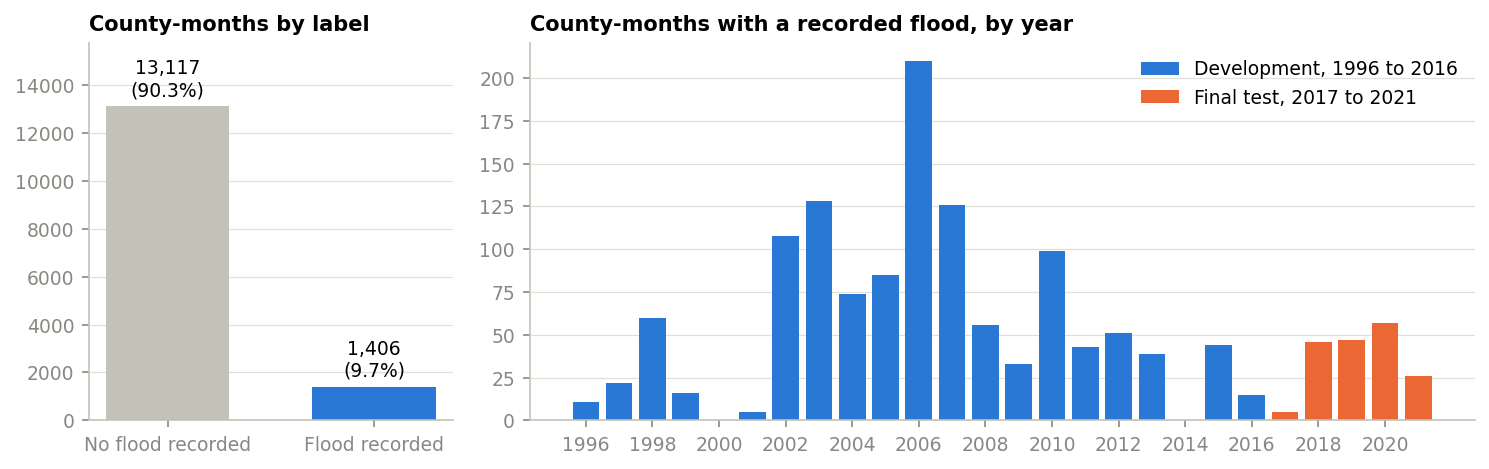

In [3]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, ".")
from riskengine.ml import train

TRAINING_SET = Path("data/processed/training_set.csv")

MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"
COLOURS = {
    "logreg": "#2a78d6",
    "random-forest": "#eb6834",
    "gradient-boosting": "#1baf7a",
    "season-only": MUTED,
    "base-rate": AXIS,
}
LABELS = {
    "logreg": "Logistic Regression",
    "random-forest": "Random Forest",
    "gradient-boosting": "Gradient Boosting",
    "season-only": "Season only",
    "base-rate": "Base rate",
}
BANDS = ["Low", "Moderate", "High", "Very High"]
plt.rcParams.update({
    "figure.dpi": 150,
    "figure.facecolor": "white",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": AXIS,
    "axes.axisbelow": True,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.frameon": False,
})

rows = pd.read_csv(TRAINING_SET, parse_dates=["date"])
rows = rows[rows["date"].dt.year >= train.FIRST_TRAINING_YEAR]
by_year = rows.groupby(rows["date"].dt.year)["flood"].sum()

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1, 2.6]})

counts = [int((rows["flood"] == 0).sum()), int((rows["flood"] == 1).sum())]
bars = left.bar(["No flood recorded", "Flood recorded"], counts, color=[AXIS, COLOURS["logreg"]], width=0.6)
left.bar_label(bars, [f"{count:,}\n({count / len(rows):.1%})" for count in counts], padding=3)
left.set_ylim(0, max(counts) * 1.2)
left.set_title("County-months by label")
left.grid(axis="x", visible=False)

is_test = by_year.index >= train.FINAL_TEST_FROM
right.bar(by_year.index[~is_test], by_year[~is_test], color=COLOURS["logreg"], width=0.8,
          label=f"Development, {by_year.index.min()} to {train.FINAL_TEST_FROM - 1}")
right.bar(by_year.index[is_test], by_year[is_test], color=COLOURS["random-forest"], width=0.8,
          label=f"Final test, {train.FINAL_TEST_FROM} to {by_year.index.max()}")
right.set_xticks(by_year.index[::2])
right.set_title("County-months with a recorded flood, by year")
right.grid(axis="x", visible=False)
right.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 4. Train

Compares Logistic Regression, Random Forest and Gradient Boosting, holding out whole years at a time, against two baselines: always guessing the base rate, and a model that knows only the month. Then refits the best one on all the data and calibrates its probabilities if that helps on held-out years. Takes a few minutes.

In [4]:
from geodata.services.climate_indices import fetch_dmi, fetch_oni

artifact, metrics = train.train(TRAINING_SET, fetch_oni(), fetch_dmi())
train.save(artifact, metrics)
print("Trained", artifact["version"])

Trained flood-random-forest-20261006


## 5. How good is it?

All figures are on years the model did not see. **Average precision** is the one the winner is picked on. Compare it with both baselines: beating the base rate shows the model knows *something*; beating the season-only model shows rainfall, the ocean indices and terrain add something beyond "it is the rainy season". **Brier** is lower-is-better.

In [5]:
print(f"{metrics['rows']} county-months from {metrics['period'][0][:4]}, {metrics['positives']} with a recorded flood "
      f"(base rate {metrics['base_rate']:.1%}); rainfall: {metrics['rain_source']}")
print(f"Selected {metrics['selected']}: average precision {metrics['lift_over_base_rate']}x the base rate, "
      f"{metrics['lift_over_season_only']}x the season-only model. Calibration kept: {metrics['calibration']}")
comparison = pd.DataFrame(metrics["comparison"]).T
for name, scores in metrics["baselines"].items():
    comparison.loc[f"({name})"] = pd.Series(scores)
comparison

14523 county-months from 1996, 1406 with a recorded flood (base rate 9.7%); rainfall: open-meteo-point
Selected random-forest: average precision 2.62x the base rate, 2.05x the season-only model. Calibration kept: none


,roc_auc,average_precision,brier
logreg,0.7655,0.2385,0.0830
random-forest,0.7867,0.2535,0.0798
gradient-boosting,0.7499,0.2154,0.0856
(base-rate),0.5000,0.0968,0.0874
(season-only),0.5645,0.1235,0.0873


The same comparison as a chart. The grey bars are the two baselines.

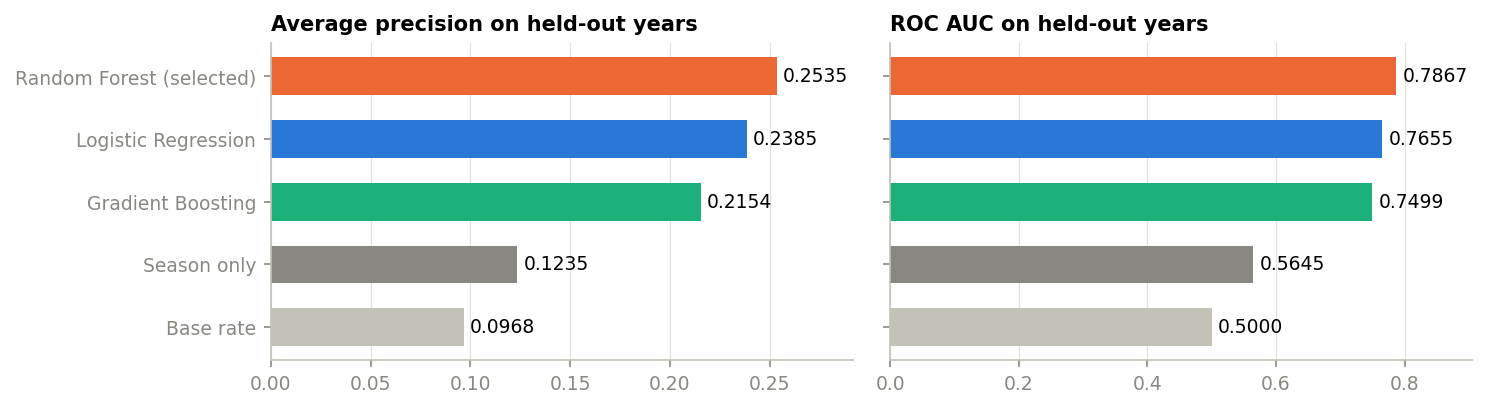

In [6]:
scores = {**metrics["comparison"], **metrics["baselines"]}
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (metric, title) in zip(axes, [("average_precision", "Average precision"), ("roc_auc", "ROC AUC")]):
    order = sorted(scores, key=lambda name: scores[name]["average_precision"])
    bars = ax.barh(
        [LABELS[name] + (" (selected)" if name == metrics["selected"] else "") for name in order],
        [scores[name][metric] for name in order],
        color=[COLOURS[name] for name in order],
        height=0.6,
    )
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.set_xlim(0, max(scores[name][metric] for name in order) * 1.15)
    ax.set_title(f"{title} on held-out years")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

The curves behind those two numbers. This repeats the cross-validation of step 4 (same folds, same seed) to get each row's probability from a model that never saw its year; the scores printed underneath must match the table above.

**ROC**: how many floods are caught against how many non-floods are wrongly flagged, as the warning threshold moves. The diagonal is guessing. **Precision-recall**: of the warnings given, how many were floods, against how many floods were caught. The dashed line is the base rate.

{'logreg': 0.2385, 'random-forest': 0.2535, 'gradient-boosting': 0.2154}


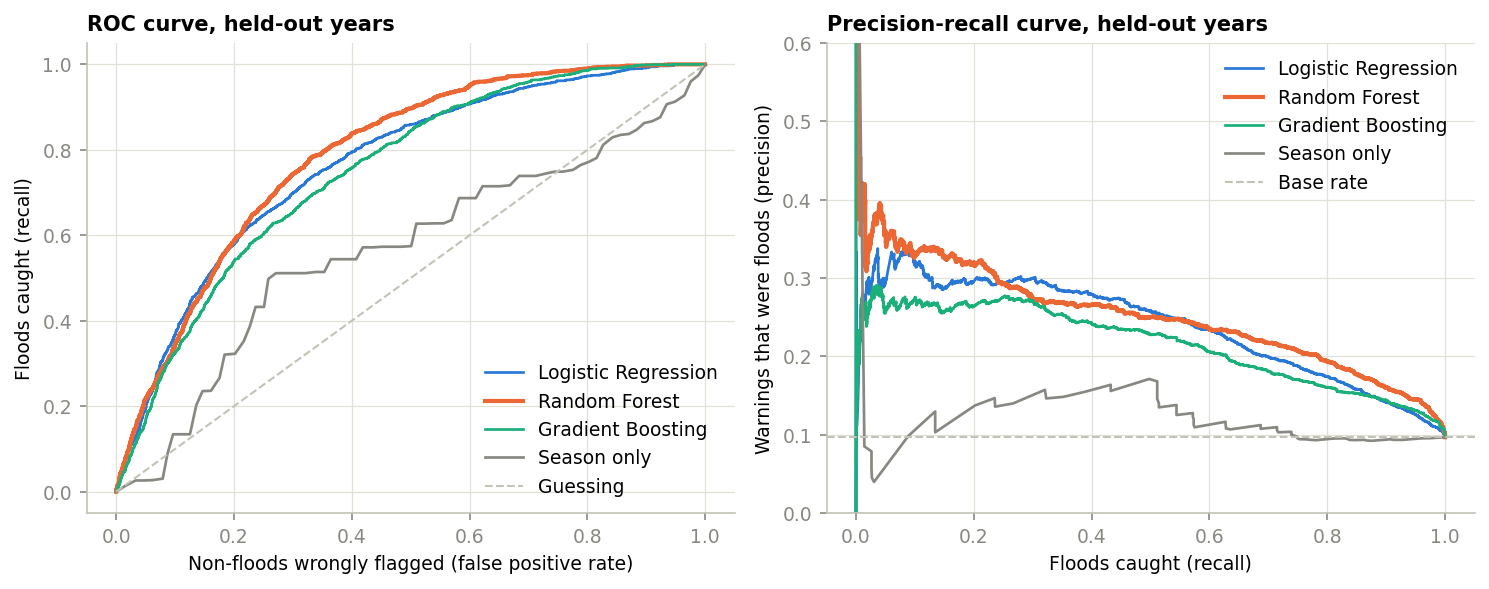

In [7]:
from sklearn.metrics import precision_recall_curve, roc_curve

data = train.load_training_set(TRAINING_SET)
chosen = train.select(data)
held_out = {**chosen.held_out, "season-only": chosen.season}
print({name: scores["average_precision"] for name, scores in chosen.comparison.items()})

fig, (roc, pr) = plt.subplots(1, 2, figsize=(10, 4))
for name, probabilities in held_out.items():
    style = {"color": COLOURS[name], "label": LABELS[name], "linewidth": 2 if name == chosen.best else 1.3}
    false_alarms, caught, _ = roc_curve(data.y, probabilities)
    roc.plot(false_alarms, caught, **style)
    precision, recall, _ = precision_recall_curve(data.y, probabilities)
    pr.plot(recall, precision, **style)
roc.plot([0, 1], [0, 1], color=AXIS, linestyle="--", linewidth=1, label="Guessing")
roc.set_xlabel("Non-floods wrongly flagged (false positive rate)")
roc.set_ylabel("Floods caught (recall)")
roc.set_title("ROC curve, held-out years")
roc.legend(loc="lower right")
pr.axhline(data.y.mean(), color=AXIS, linestyle="--", linewidth=1, label="Base rate")
pr.set_xlabel("Floods caught (recall)")
pr.set_ylabel("Warnings that were floods (precision)")
pr.set_ylim(0, 0.6)  # the first few rows jump to 1.0; the comparison is below that
pr.set_title("Precision-recall curve, held-out years")
pr.legend(loc="upper right")
fig.tight_layout()
plt.show()

How often a flood was actually recorded in each risk band, on held-out years, after calibration. The bands are only useful if this rises from Low to Very High, and `mean_predicted` should sit close to `observed_flood_rate`.

In [8]:
pd.DataFrame(metrics["band_calibration"]).set_index("band")

,rows,mean_predicted,observed_flood_rate
band,,,
low,7048,0.0194,0.0231
moderate,2778,0.0726,0.0846
high,2484,0.1423,0.1703
very_high,2213,0.3120,0.2643


Bars are the share of county-months in each band that had a recorded flood; the dot is what the model said on average. Left is cross-validation, right is the 2017 to 2021 final test. The bands are useful if the bars rise from Low to Very High, and trustworthy as probabilities only if the dots sit on top of the bars.

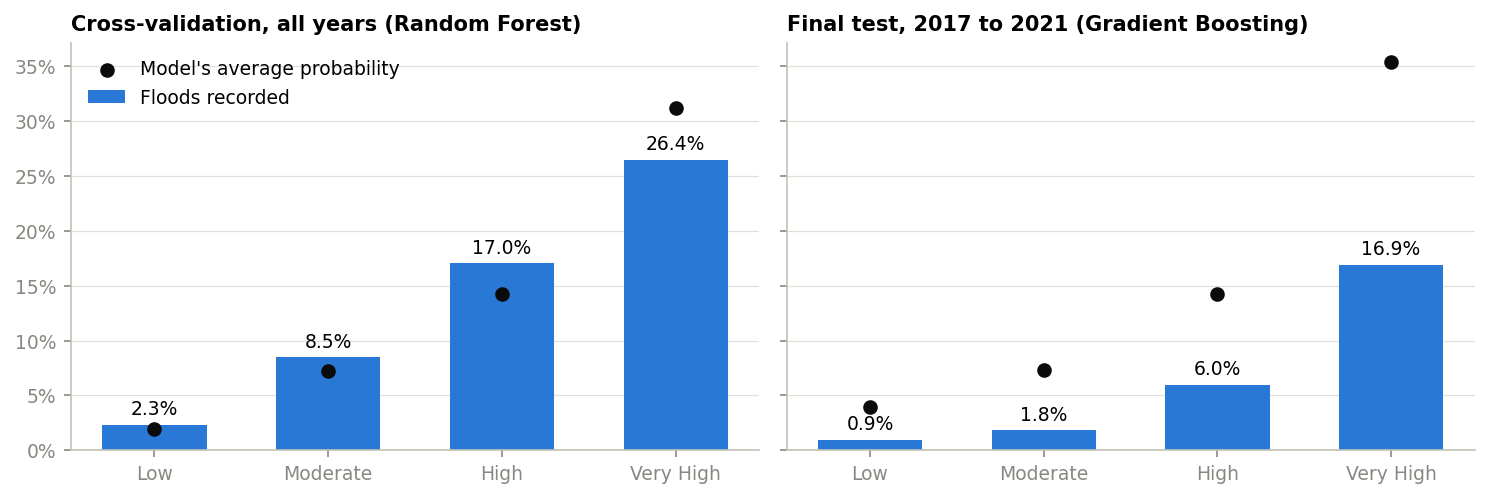

In [9]:
panels = [
    (f"Cross-validation, all years ({LABELS[metrics['selected']]})", metrics["band_calibration"]),
    (f"Final test, 2017 to 2021 ({LABELS[metrics['final_test']['selected']]})", metrics["final_test"]["band_calibration"]),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (title, bands) in zip(axes, panels):
    observed = [100 * (band["observed_flood_rate"] or 0) for band in bands]
    predicted = [100 * (band["mean_predicted"] or 0) for band in bands]
    bars = ax.bar(BANDS, observed, color=COLOURS["logreg"], width=0.6, label="Floods recorded")
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.scatter(BANDS, predicted, color="#0b0b0b", s=36, zorder=3, label="Model's average probability")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter("{x:.0f}%")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

Calibration on held-out years. ROC AUC barely moves (calibration does not change the ranking); the one with the lowest Brier is kept.

In [10]:
pd.DataFrame(metrics["calibration_comparison"]).T

,roc_auc,average_precision,brier
none,0.7867,0.2535,0.0798
sigmoid,0.7770,0.2413,0.0802
isotonic,0.7614,0.2166,0.0814


Average precision in each fold, with the years it held out. The pooled figures above hide how much the result depends on which years are held out; the spread here is the honest error bar.

In [11]:
folds = pd.DataFrame(
    {name: scores["average_precision"] for name, scores in fold["scores"].items()}
    | {"years": ", ".join(map(str, fold["years"])), "floods": fold["positives"]}
    for fold in metrics["folds"]
)
display(folds)
pd.DataFrame(metrics["fold_summary"]).T

,logreg,random-forest,gradient-boosting,season-only,years,floods
0,0.2472,0.2875,0.3011,0.2866,"1996, 2002, 2008, 2014, 2020",232
1,0.1659,0.1680,0.1437,0.0785,"2001, 2007, 2013, 2019, 2021",243
2,0.4799,0.3512,0.2382,0.2516,"2000, 2006, 2012, 2018",307
3,0.1713,0.1948,0.1624,0.0702,"1999, 2005, 2011, 2017",149
4,0.3136,0.3650,0.3241,0.3179,"1998, 2004, 2010, 2016",248
5,0.2202,0.4134,0.2622,0.2074,"1997, 2003, 2009, 2015",227


,average_precision_mean,average_precision_sd,roc_auc_mean,roc_auc_sd
logreg,0.2663,0.1179,0.7666,0.0701
random-forest,0.2967,0.0983,0.7986,0.0545
gradient-boosting,0.2386,0.0729,0.7520,0.0559
season-only,0.2020,0.1055,0.6049,0.1669


The same per-fold scores as a chart, and which years each fold holds out. A fold is always whole years, never a random sample of rows.

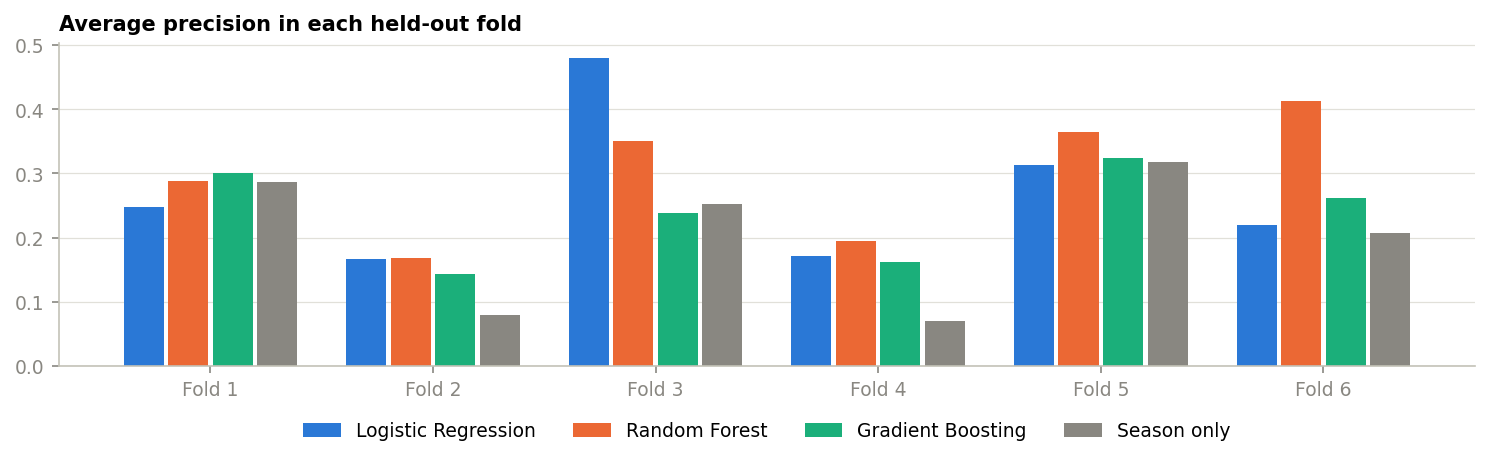

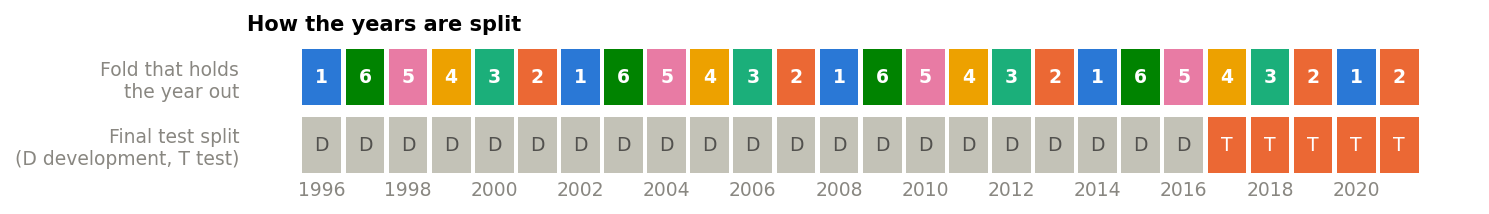

In [12]:
fold_names = [f"Fold {index + 1}" for index in range(len(metrics["folds"]))]
models = [*metrics["comparison"], "season-only"]
fig, ax = plt.subplots(figsize=(10, 3.2))
width = 0.8 / len(models)
for offset, name in enumerate(models):
    ax.bar(
        np.arange(len(fold_names)) + (offset - (len(models) - 1) / 2) * width,
        [fold["scores"][name]["average_precision"] or 0 for fold in metrics["folds"]],
        width=width * 0.9,
        color=COLOURS[name],
        label=LABELS[name],
    )
ax.set_xticks(np.arange(len(fold_names)), fold_names)
ax.set_title("Average precision in each held-out fold")
ax.grid(axis="x", visible=False)
ax.legend(ncols=len(models), loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

FOLD_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
fold_of = {year: index for index, fold in enumerate(metrics["folds"]) for year in fold["years"]}
years = sorted(fold_of)
fig, ax = plt.subplots(figsize=(10, 1.5))
for year in years:
    ax.bar(year, 1, bottom=1.2, width=0.9, color=FOLD_COLOURS[fold_of[year] % len(FOLD_COLOURS)])
    ax.text(year, 1.7, str(fold_of[year] + 1), ha="center", va="center", color="white", fontweight="bold")
    final = year >= metrics["final_test"]["test_from"]
    ax.bar(year, 1, bottom=0, width=0.9, color=COLOURS["random-forest"] if final else AXIS)
    ax.text(year, 0.5, "T" if final else "D", ha="center", va="center", color="white" if final else "#52514e")
ax.set_xticks(years[::2])
ax.set_yticks([0.5, 1.7], ["Final test split\n(D development, T test)", "Fold that holds\nthe year out"])
ax.tick_params(length=0)
ax.grid(visible=False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("How the years are split")
fig.tight_layout()
plt.show()

What happens if a probability above each band edge is treated as a warning. A false negative is a recorded flood with no warning.

In [13]:
pd.DataFrame(metrics["threshold_errors"]).set_index("threshold")

,true_positives,false_positives,false_negatives,true_negatives,precision,recall,specificity
threshold,,,,,,,
0.05,1243,6232,163,6885,0.1663,0.8841,0.5249
0.10,1008,3689,398,9428,0.2146,0.7169,0.7188
0.20,585,1628,821,11489,0.2643,0.4161,0.8759


The 10% row of that table as a confusion matrix: a High or Very High band counts as a warning.

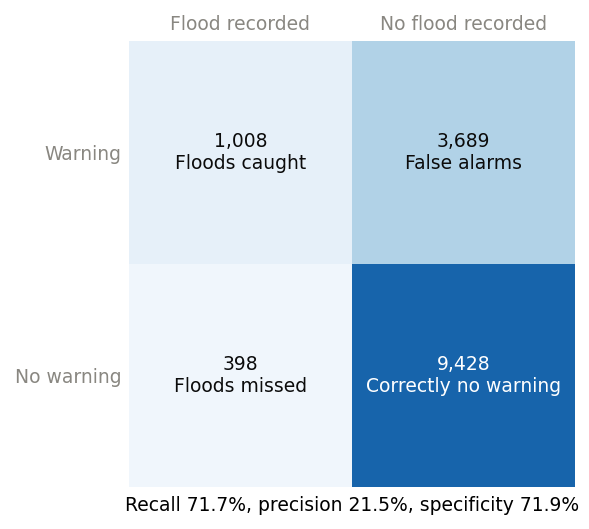

In [14]:
errors = next(row for row in metrics["threshold_errors"] if row["threshold"] == 0.10)
matrix = np.array([
    [errors["true_positives"], errors["false_positives"]],
    [errors["false_negatives"], errors["true_negatives"]],
])
names = [["Floods caught", "False alarms"], ["Floods missed", "Correctly no warning"]]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.25)
for row in range(2):
    for column in range(2):
        ax.text(
            column, row, f"{matrix[row, column]:,}\n{names[row][column]}",
            ha="center", va="center",
            color="white" if matrix[row, column] > matrix.max() * 0.6 else "#0b0b0b",
        )
ax.set_xticks([0, 1], ["Flood recorded", "No flood recorded"])
ax.set_yticks([0, 1], ["Warning", "No warning"])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(visible=False)
ax.spines[:].set_visible(False)
ax.set_xlabel(
    f"Recall {errors['recall']:.1%}, precision {errors['precision']:.1%}, specificity {errors['specificity']:.1%}"
)
fig.tight_layout()
plt.show()

The final test. The years from 2017 on were set aside, the model and calibration were chosen again on 1996 to 2016 alone, and 2017 to 2021 were scored once. This is the figure to trust most, and it is the least flattering. The first row is the model that choice picked; the others are shown for the record.

In [15]:
test = metrics["final_test"]
print(f"{test['rows']} county-months, {test['positives']} floods, {test['test_years']}")
display(pd.DataFrame(
    {f"{test['selected']} (chosen)": test["scores"]} | test["other_candidates"] | test["baselines"]
).T)
pd.DataFrame(test["band_calibration"]).set_index("band")

2679 county-months, 181 floods, [2017, 2021]


,roc_auc,average_precision,brier
gradient-boosting (chosen),0.7667,0.1532,0.0753
logreg,0.8515,0.2745,0.0674
random-forest,0.7823,0.1858,0.0820
base-rate,0.5000,0.0676,0.0643
season-only,0.6935,0.1768,0.0626


,rows,mean_predicted,observed_flood_rate
band,,,
low,428,0.0393,0.0093
moderate,769,0.0729,0.0182
high,800,0.1427,0.0600
very_high,682,0.3532,0.1686


The commit, data and seed this result came from. `git_commit` is empty on Colab, because the bundle is not a git checkout: note the commit the bundle was built from.

In [16]:
metrics["provenance"]

{'git_commit': None,
 'training_set_sha256': '367173d305e66155a85ba0299f4dedee5765a73eca87989d57e2209270a45033',
 'random_state': 0,
 'scikit_learn': '1.9.1'}

How much the saved model relies on each input (tree models only). This is impurity importance: it says how much an input was used to separate floods from non-floods, not in which direction it pushes. `log_area` is a control for how the labels are made, not a cause of flooding; see `riskengine/ml/README.md`.

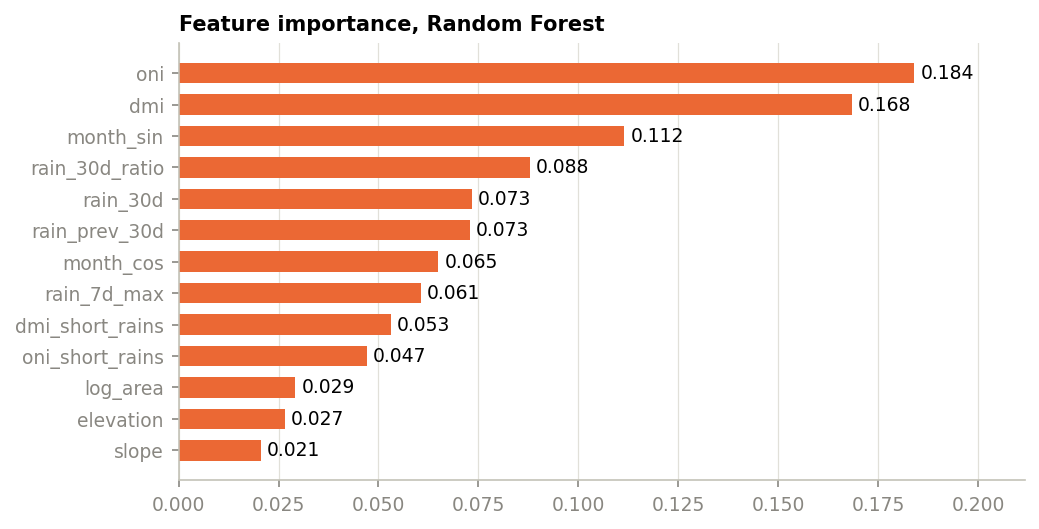

In [17]:
estimator = artifact["pipeline"][-1]
if hasattr(estimator, "feature_importances_"):
    importance = pd.Series(estimator.feature_importances_, index=artifact["features"]).sort_values()
    fig, ax = plt.subplots(figsize=(7, 3.6))
    bars = ax.barh(importance.index, importance.values, color=COLOURS[metrics["selected"]], height=0.65)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_xlim(0, importance.max() * 1.15)
    ax.set_title(f"Feature importance, {LABELS[metrics['selected']]}")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    plt.show()

What pushes the probability up or down (logistic regression only). Coefficients are per standard deviation of each input, so they can be compared with each other. `log_area` is a control for how the labels are made, not a cause of flooding; see `riskengine/ml/README.md`.

In [18]:
pd.Series(metrics.get("standardised_coefficients", {}), name="coefficient").sort_values().to_frame()

,coefficient


## 6. Download the model

Put both files in `riskengine/ml/artifacts/` in the repository, replacing what is there. Then:

```
docker compose restart web
docker compose run --rm web python manage.py seed_rainfall
docker compose run --rm web python manage.py score_regions
docker compose run --rm web python manage.py flood_outlook
```

In [19]:
files.download(str(train.ARTIFACT_PATH))
files.download(str(train.METRICS_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>